# Stage 4 — Exploratory Data Analysis & Feature Engineering
**Stakeholder:** UNEP · **Target:** `Economic Loss (Million $)` (regression)

This notebook explores the cleaned data from `01_data_cleaning.ipynb`, looks for patterns that matter for UNEP, and tests whether new features actually improve prediction.

In [1]:
from pathlib import Path
import json
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore")

# Find the project folder (works from the repo root or from notebooks/)
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA = ROOT / "data"
DOCS = ROOT / "docs"
MODELS = ROOT / "models"
DOCS.mkdir(exist_ok=True)
MODELS.mkdir(exist_ok=True)

TARGET = "Economic Loss (Million $)"
NUM_FEATURES = ["Year", "Total Waste (Tons)", "Avg Waste per Capita (Kg)", "Household Waste (%)"]
CAT_FEATURES = ["Country", "Food Category"]

# Load the cleaned dataset produced by 01_data_cleaning.ipynb
df = pd.read_csv(DATA / "cleaned_food_waste.csv")
print("Shape:", df.shape)
display(df.head())

Shape: (3575, 7)


,Country,Year,Food Category,Total Waste (Tons),Economic Loss (Million $),Avg Waste per Capita (Kg),Household Waste (%)
0,Australia,2021,Beverages,2967.07,2889.80,144.41,44.07
1,France,2021,Meat & Seafood,48643.30,45212.72,52.73,69.48
2,Saudi Arabia,2023,Frozen Food,1410.30,1386.31,NaN,64.73
3,UK,2023,Bakery Items,18014.05,15852.44,180.34,61.14
4,Japan,2018,Bakery Items,27534.23,29110.52,162.58,69.77


## 4.1 Summary of the cleaned data

In [2]:
# Summary statistics after cleaning
display(df.describe().round(2))

# How many rows per food category and per country
print("Rows per food category:")
display(df["Food Category"].value_counts().to_frame("Rows"))
print("Number of countries:", df["Country"].nunique())
print("Years covered:", df["Year"].min(), "to", df["Year"].max())

,Year,Total Waste (Tons),Economic Loss (Million $),Avg Waste per Capita (Kg),Household Waste (%)
count,3575.00,3355.00,3575.00,3346.00,3459.00
mean,2021.02,25155.55,25212.82,109.82,50.21
std,2.00,14290.04,14666.63,51.91,11.57
min,2018.00,502.61,406.69,20.09,30.04
25%,2019.00,12891.60,12770.28,64.36,40.15
50%,2021.00,25304.57,24683.22,110.66,50.43
75%,2023.00,37575.04,37351.34,154.91,60.25
max,2024.00,49990.76,59228.93,199.97,69.99


Rows per food category:


,Rows
Food Category,
Prepared Food,507
Bakery Items,463
Beverages,452
Meat & Seafood,434
Fruits & Vegetables,434
Dairy Products,432
Grains & Cereals,427
Frozen Food,426


Number of countries: 20
Years covered: 2018 to 2024


📝 **Interpretation :** what does the cleaned data look like? Are categories and countries balanced?
2. What the cleaned data looks like

After cleaning, the dataset now contains 3575 rows with 20 countries between the timeline 2018 to 2024. Both the food categories and countries are fairly evenly distributed without major imbalances: food categories range from 426 rows (Frozen Food) to 507 rows (Prepared Food, which has 44 to 81 more rows than the others), while countries range from 158 rows (South Korea) to 209 rows (Germany). Looking at the summary count row, some predictor columns still contain missing values mostly Total Waste, which has 220 missing entries. Because Total Waste is the strongest predictor of Economic Loss, handling these missing values properly is critical and is addressed in the following sections

## 4.2 Distribution of the target (Economic Loss)

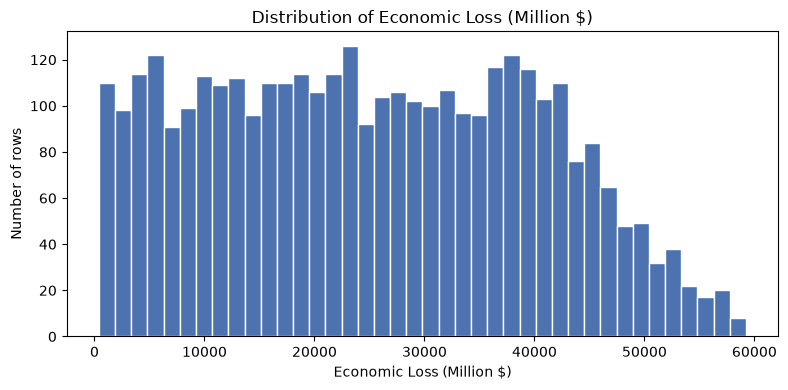

Skewness: 0.123


In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df[TARGET], bins=40, color="#4C72B0", edgecolor="white")
ax.set_title("Distribution of Economic Loss (Million $)")
ax.set_xlabel("Economic Loss (Million $)")
ax.set_ylabel("Number of rows")
plt.tight_layout()
plt.show()

print("Skewness:", round(df[TARGET].skew(), 3))

📝 **Interpretation :** what shape is the distribution? Is it skewed? Does the target need transforming?

The target variable has a skewness of 0.123, which means the values are nearly symmetric and not heavily leaning towards one end. Visually, the histogram is fairly flat, showing an even spread across low to high values instead of forming a traditional bell curve. Because there is virtually no skew or extreme tail pulling the data, applying a log transformation is unnecessary and would not be expected to improve model performance.

## 4.3 Relationship between Total Waste and Economic Loss

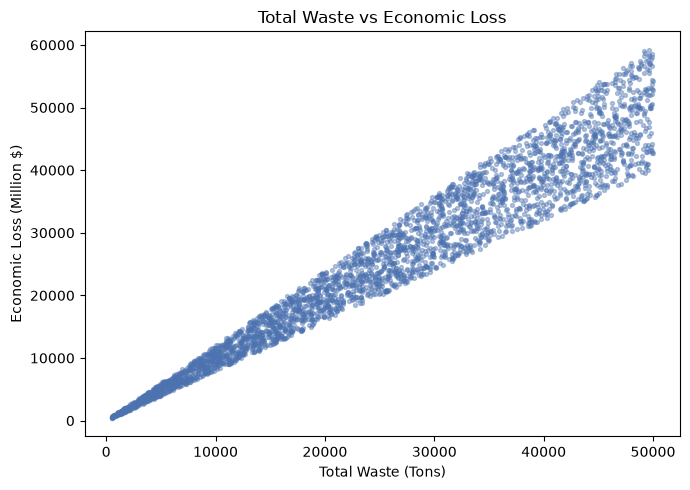

,Year,Total Waste (Tons),Avg Waste per Capita (Kg),Household Waste (%),Economic Loss (Million $)
Year,1.000,-0.008,0.014,-0.024,-0.005
Total Waste (Tons),-0.008,1.000,0.023,0.038,0.975
Avg Waste per Capita (Kg),0.014,0.023,1.000,-0.035,0.023
Household Waste (%),-0.024,0.038,-0.035,1.000,0.028
Economic Loss (Million $),-0.005,0.975,0.023,0.028,1.000


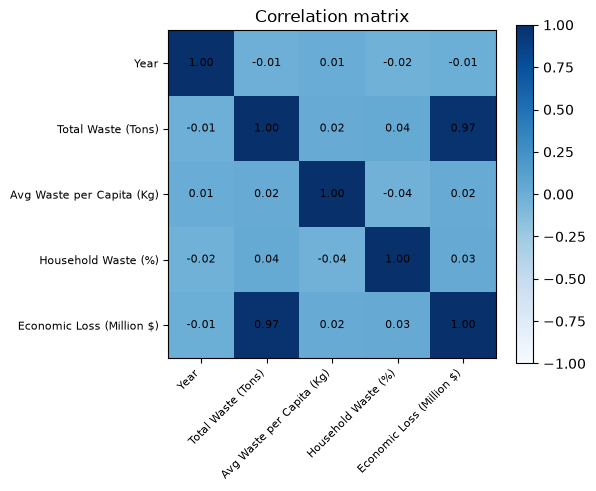

In [4]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(df["Total Waste (Tons)"], df[TARGET], s=8, alpha=0.4, color="#4C72B0")
ax.set_title("Total Waste vs Economic Loss")
ax.set_xlabel("Total Waste (Tons)")
ax.set_ylabel("Economic Loss (Million $)")
plt.tight_layout()
plt.show()

# Correlation of every numeric feature with the target
corr = df[NUM_FEATURES + [TARGET]].corr()
display(corr.round(3))

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap="Blues", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(corr)))
ax.set_yticklabels(corr.columns, fontsize=8)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im)
ax.set_title("Correlation matrix")
plt.tight_layout()
plt.show()

📝 **Interpretation :** which feature is strongly related to Economic Loss, and which are not? What does this mean for the model?

Total Waste and Economic Loss show a very strong positive correlation of r = 0.975, forming an almost straight line on the scatter plot. All other numeric features sit between $-0.03$ and $+0.03$ effectively zero meaning they have almost no linear relationship with Economic Loss. For modeling, this indicates that Total Waste will nearly carry all the predictive weight and that a linear model is a strong fit. Because correlation only measures numeric columns, Country and Food Category are evaluated separately in the following section.

## 4.4 Cost per ton by food category and country
If some food categories or countries lose **more money per ton**, the model could use that to tell UNEP where waste is most expensive.

,mean,median,std
Food Category,,,
Beverages,0.999,0.994,0.115
Grains & Cereals,0.997,0.994,0.118
Prepared Food,0.998,0.999,0.111
Dairy Products,1.002,1.001,0.110
Meat & Seafood,0.996,1.001,0.116
Bakery Items,0.997,1.003,0.114
Frozen Food,1.002,1.003,0.114
Fruits & Vegetables,1.009,1.017,0.115


,mean,median,std
Country,,,
UK,0.983,0.972,0.119
Germany,0.999,0.984,0.111
South Korea,0.994,0.990,0.116
France,0.991,0.990,0.115
Japan,0.991,0.990,0.122
Brazil,0.994,0.991,0.118
Spain,0.996,0.992,0.113
South Africa,1.002,0.993,0.104
Mexico,0.998,0.994,0.111


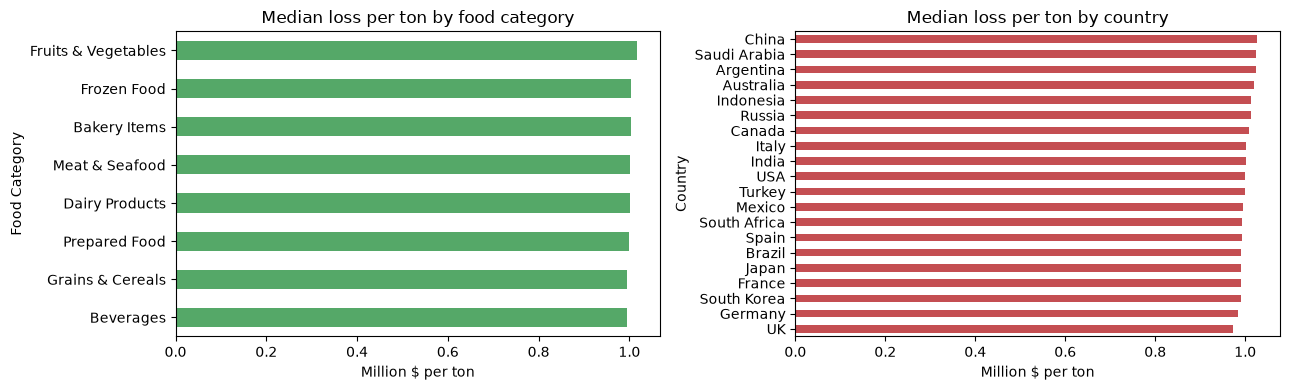

In [5]:
# Economic loss per ton (only rows where Total Waste is known)
known = df.dropna(subset=["Total Waste (Tons)"]).copy()
known["Loss per Ton"] = known[TARGET] / known["Total Waste (Tons)"]

by_category = known.groupby("Food Category")["Loss per Ton"].agg(["mean", "median", "std"]).round(3)
by_country = known.groupby("Country")["Loss per Ton"].agg(["mean", "median", "std"]).round(3)
display(by_category.sort_values("median"))
display(by_country.sort_values("median"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
by_category["median"].sort_values().plot.barh(ax=axes[0], color="#55A868")
axes[0].set_title("Median loss per ton by food category")
axes[0].set_xlabel("Million $ per ton")
by_country["median"].sort_values().plot.barh(ax=axes[1], color="#C44E52")
axes[1].set_title("Median loss per ton by country")
axes[1].set_xlabel("Million $ per ton")
plt.tight_layout()
plt.show()

📝 **Interpretation:** is the cost per ton different across categories or countries? What does that mean for UNEP — is it the *amount* of waste or the *type* of food that drives the loss?

Across all groups the median economic loss per ton sits right around $1.0 million per ton, ranging in a narrow way from $0.994 to $1.017 million per ton across food categories and $0.972 to $1.026 million per ton across countries. Because the variation within each group is noticeably larger than the tiny differences between group medians, neither food type nor country meaningfully changes the cost per ton. For UNEP, the takeaway is straightforward: total financial loss is driven by the sheer volume of food wasted rather than the specific category or country.

## 4.5 Where is the total loss highest? (business view)

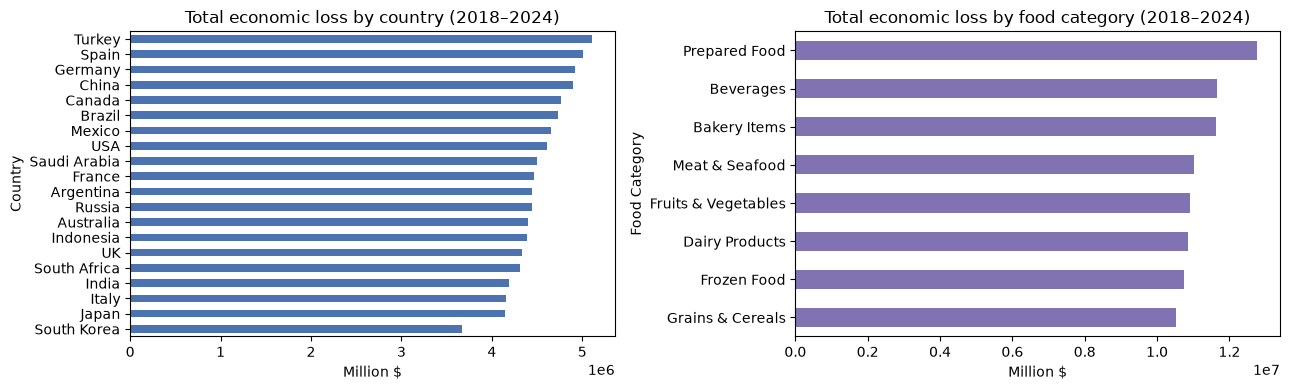

,,Total loss (Million $)
Country,Food Category,
Canada,Bakery Items,934389.6
USA,Bakery Items,931260.7
Brazil,Prepared Food,869455.4
Turkey,Prepared Food,848847.5
UK,Frozen Food,835200.9


In [6]:
loss_by_country = df.groupby("Country")[TARGET].sum().sort_values(ascending=False)
loss_by_category = df.groupby("Food Category")[TARGET].sum().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
loss_by_country.sort_values().plot.barh(ax=axes[0], color="#4C72B0")
axes[0].set_title("Total economic loss by country (2018–2024)")
axes[0].set_xlabel("Million $")
loss_by_category.sort_values().plot.barh(ax=axes[1], color="#8172B2")
axes[1].set_title("Total economic loss by food category (2018–2024)")
axes[1].set_xlabel("Million $")
plt.tight_layout()
plt.show()

# Top 5 country + category combinations by total loss
top_combos = (df.groupby(["Country", "Food Category"])[TARGET]
                .sum().sort_values(ascending=False).head(5).round(1).to_frame("Total loss (Million $)"))
display(top_combos)

📝 **Interpretation: ** which countries and categories lose the most? Remember that the number of rows per country is not identical — does that affect this ranking?

In the top 5 table, Canada–Bakery is the highest-loss combination at roughly 934,390 M$, while on the other hand, the bar charts show Turkey, Spain, and Germany taking a lead in overall losses by country and Prepared Food, Beverages, and Bakery Items leading by food category. However, because these totals are sums and countries do not all have the same number of records so a group with more entries will rank higher simply because more rows are being added together. thats why comparing the mean economic loss per record instead would give us a fair comparsion.


## 4.6 Trend over time

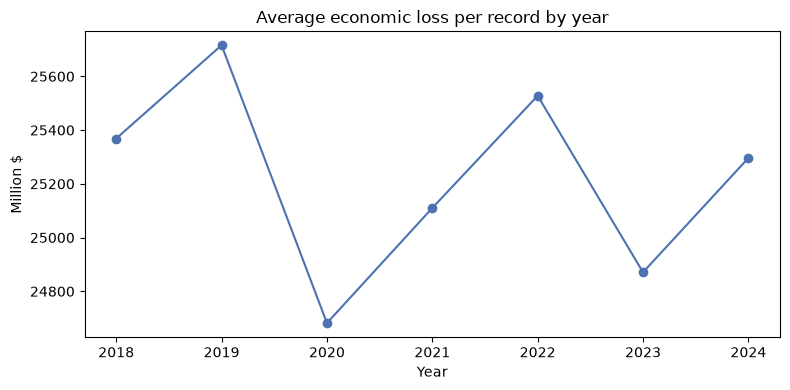

,sum,mean
Year,,
2018,12557472.4,25368.6
2019,12883632.0,25715.8
2020,13081403.7,24681.9
2021,13233018.5,25110.1
2022,11946979.2,25527.7
2023,13380534.0,24870.9
2024,13052790.2,25296.1


In [7]:
yearly = df.groupby("Year")[TARGET].agg(["sum", "mean"])
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(yearly.index, yearly["mean"], marker="o", color="#4C72B0")
ax.set_title("Average economic loss per record by year")
ax.set_xlabel("Year")
ax.set_ylabel("Million $")
plt.tight_layout()
plt.show()
display(yearly.round(1))


📝 **Interpretation (write in your own words):** is there a trend over the years?

The average stays between around 24,600 and 25,700 M$ every year, with no clear trend. we can see that the 2022 sum is the lowest, but checking sum ÷ mean shows it was just fewer rows that year rather than a real drop.

## 4.7 Feature engineering — tested, not assumed
We create candidate features and test each one with 5-fold cross-validation on the **training split only** (same split as the modelling notebook), so the test set is never seen here.

Candidate features:
- `Years Since 2018` — a simple time trend
- `Waste Missing` — flag for rows where Total Waste is unknown
- `Waste × Category` — lets the price per ton differ by food category

In [8]:
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression

def add_features(data):
    out = data.copy()
    out["Years Since 2018"] = out["Year"] - 2018
    out["Waste Missing"] = out["Total Waste (Tons)"].isna().astype(int)
    # Interaction: total waste for each food category in its own column
    for category in sorted(data["Food Category"].unique()):
        out[f"Waste x {category}"] = out["Total Waste (Tons)"].where(out["Food Category"] == category, 0)
    return out

data_fe = add_features(df)
X_all = data_fe.drop(columns=[TARGET])
y_all = data_fe[TARGET]

# Same split as 03_modeling.ipynb; feature tests use the training part only
X_train, X_test, y_train, y_test = train_test_split(X_all, y_all, test_size=0.2, random_state=42)
cv = KFold(n_splits=5, shuffle=True, random_state=42)

def cv_r2(num_cols, cat_cols):
    pre = ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ])
    model = Pipeline([("pre", pre), ("reg", LinearRegression())])
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="r2")
    return scores.mean(), scores.std()

interaction_cols = [c for c in X_all.columns if c.startswith("Waste x ")]
feature_sets = {
    "A: Total Waste only": (["Total Waste (Tons)"], []),
    "B: All original features": (NUM_FEATURES, CAT_FEATURES),
    "C: B + Years Since 2018": (NUM_FEATURES + ["Years Since 2018"], CAT_FEATURES),
    "D: B + Waste Missing flag": (NUM_FEATURES + ["Waste Missing"], CAT_FEATURES),
    "E: B + Waste x Category": (NUM_FEATURES + interaction_cols, CAT_FEATURES),
}

rows = []
for name, (num_cols, cat_cols) in feature_sets.items():
    mean, std = cv_r2(num_cols, cat_cols)
    rows.append({"Feature set": name, "CV R² (mean)": round(mean, 4), "CV R² (std)": round(std, 4)})
feature_tests = pd.DataFrame(rows)
display(feature_tests)
feature_tests.to_csv(DOCS / "feature_tests.csv", index=False)

,Feature set,CV R² (mean),CV R² (std)
0,A: Total Waste only,0.8964,0.0108
1,B: All original features,0.8949,0.0110
2,C: B + Years Since 2018,0.8949,0.0110
3,D: B + Waste Missing flag,0.8941,0.0108
4,E: B + Waste x Category,0.8936,0.0113


### Ablation: what happens if we remove one original feature at a time?

In [9]:
base_mean, _ = cv_r2(NUM_FEATURES, CAT_FEATURES)
ablation = []
for feature in NUM_FEATURES + CAT_FEATURES:
    num_cols = [c for c in NUM_FEATURES if c != feature]
    cat_cols = [c for c in CAT_FEATURES if c != feature]
    mean, _ = cv_r2(num_cols, cat_cols)
    ablation.append({"Removed feature": feature, "CV R² without it": round(mean, 4),
                     "Change vs all features": round(mean - base_mean, 4)})
ablation = pd.DataFrame(ablation).sort_values("Change vs all features")
display(ablation)
ablation.to_csv(DOCS / "feature_ablation.csv", index=False)

,Removed feature,CV R² without it,Change vs all features
1,Total Waste (Tons),-0.0180,-0.9129
3,Household Waste (%),0.8948,-0.0001
0,Year,0.8950,0.0001
2,Avg Waste per Capita (Kg),0.8951,0.0001
5,Food Category,0.8954,0.0005
4,Country,0.8959,0.0010


📝 **Interpretation ** which engineered features helped and which did not? Which original feature matters most? Which features will you keep for modelling, and why?

Removing Total Waste drops CV R² from around 0.895 to −0.018, while removing anything else changes it by ≤0.001. From feature_tests.csv none of the engineered features (Years Since 2018, Waste Missing flag, Waste × Category) improved on the original set, and "Total Waste only" scored highest at 0.8964. 
Decision: All three engineered features were dropped because they didnt improve predictive performance, while all original features—including Country and Food Category—were retained despite the small 0.0015 R² difference (0.8949 vs. 0.8964). Keeping Country and Food Category is essential for the UNEP applications functionality because it allows users to filter, compare, and identify the top 5 country–food category combinations driving economic loss rather than relying on waste volume alone.